# Visual Sudoku Solving Using Constraint Satisfaction Problem (CSP)

**Kelompok 5, Konsep Kecerdasan Artifisial**

| Nama | NRP |
|---|---|
| Anang Ardhiansyah | 5025251118 |
| Farrel Satria Mukti | 5025251138 |
| Dewa Ngakan Putu Sunyananda Triyanca | 5025251152 |
| Fazli Irham Ramadhan Abdillah | 5025251178 |
| I Dewa Nyoman Acarya Wibawantra | 5025251222 |

Implementasi dari artikel: Mulamba, M., Mandi, J., Mahmutoğulları, A. İ., & Guns, T. (2024). *Perception-based constraint solving for sudoku images*. Constraints, 29, 112–151. https://doi.org/10.1007/s10601-024-09372-9

Ide utama: CNN membaca 81 sel gambar Sudoku dan menghasilkan probabilitas tiap kelas, lalu solver Constraint Programming (CPMpy + OR-Tools CP-SAT) memilih **bacaan paling mungkin yang tetap memenuhi aturan Sudoku** (*joint inference*).

Struktur notebook:
1. Setup & Load Data
2. Preprocessing
3. Training CNN (Persepsi)
4. Kalibrasi
5. Model CP & Solver
6. Evaluasi & Visualisasi (Skenario 1, 2, 3)

> **Catatan Colab:** pilih *Runtime > Change runtime type > GPU*. Kalau bobot model sudah dilatih di lokal, upload folder `weights/` lalu set `TRAIN = False`.

## 1. Setup & Load Data

In [30]:
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    # highspy bawaan Colab (Python 3.13) rusak dan membuat import cpmpy gagal, solver kita pakai OR-Tools
    !pip -q uninstall -y highspy
    !pip -q install cpmpy ortools

In [31]:
import math
import os
import pickle
import tarfile
import time
import urllib.request
from pathlib import Path

import cpmpy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T

try:
    # Python dari uv/python.org di macOS kadang tidak punya sertifikat SSL (download bobot ResNet gagal)
    import certifi
    os.environ.setdefault("SSL_CERT_FILE", certifi.where())
except ImportError:
    pass

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("device :", DEVICE)
print("torch  :", torch.__version__)
print("cpmpy  :", cp.__version__)

device : mps
torch  : 2.14.1
cpmpy  : 1.1.1


### Konfigurasi

- `TRAIN = True` melatih CNN dari awal. `TRAIN = False` memuat bobot dari `WEIGHTS_DIR` (berguna untuk demo di Colab tanpa training ulang).
- Artikel memakai 5 ronde cross-validation. Default di sini 1 seed supaya cepat; isi `SEEDS = [0, 1, 2, 3, 4]` untuk eksperimen penuh.
- Dataset MNIST Visual Sudoku berisi 10.000 puzzle. `MNIST_N` mengambil subset agar training muat di laptop/Colab.

In [32]:
TRAIN = False
TUNE = False               # cari alpha dan gamma_e di validation set
SEEDS = [0]
DATASETS = ["opensky", "mnist", "assistant"]
MNIST_N = 1000
TIME_LIMIT = 30           # batas waktu solver per puzzle (detik)
PRECISION = 1e-4          # pembulatan -log P ke integer untuk CP-SAT
N_ERRORS = [0, 1, 2, 5]   # skenario 3

ROOT = Path("/content") if IN_COLAB else Path.cwd()
# Kalau pakai Google Drive:
#   from google.colab import drive; drive.mount("/content/drive")
#   ROOT = Path("/content/drive/MyDrive/KKA/program-csp")
DATA_DIR = ROOT / "data"
WEIGHTS_DIR = ROOT / "weights"
DATA_DIR.mkdir(parents=True, exist_ok=True)
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

# ResNet18 224x224 (sesuai artikel) butuh GPU, di laptop tanpa CUDA dipakai 128x128 supaya RAM cukup
RESNET_SIZE = 224 if DEVICE == "cuda" else 128

# arch: backbone CNN, size: ukuran input sel, pad: overlap antar sel, classes: 10 (blank, 1-9) atau 19 (+ printed/handwritten)
CFG = {
    "opensky":   dict(arch="lenet",    size=28,  pad=0.1, classes=10, epochs=20, lr=1e-3, bs=128),
    "mnist":     dict(arch="lenet",    size=28,  pad=0.0, classes=10, epochs=5,  lr=1e-3, bs=256),
    "assistant": dict(arch="resnet18", size=RESNET_SIZE, pad=0.1, classes=19, epochs=10, lr=1e-4, bs=32),
}

### Download dataset

Dataset replikasi artikel tersedia di KU Leuven RDR: https://doi.org/10.48804/3SUHHR (referensi [64] di artikel). Isinya tiga dataset:

| Dataset | Jumlah | Keterangan |
|---|---|---|
| OpenSky | 100 gambar | Sudoku hasil generator, rapi dan tanpa artefak |
| MNIST Visual Sudoku | 10.000 puzzle | Dari SATNet, tiap sel diisi digit MNIST (tulisan tangan) |
| Sudoku Assistant | 103 gambar | Foto kamera HP, ada angka cetak dan tulisan tangan |

Cell di bawah hanya mengunduh file yang belum ada (MNIST ±700 MB).

In [33]:
RDR_URL = "https://rdr.kuleuven.be/api/access/datafile/{}"
RDR_FILES = {"assistant": 169929, "opensky": 169930, "mnist": 169932}
RAW_FOLDER = {"assistant": "app", "opensky": "neurasp", "mnist": "mnist"}


def download_dataset(name):
    folder = DATA_DIR / "raw" / "data" / "raw_data" / RAW_FOLDER[name]
    if folder.exists():
        return folder
    tgz = DATA_DIR / f"data_{name}.tar.gz"
    if not tgz.exists():
        print(f"download {name} ...")
        urllib.request.urlretrieve(RDR_URL.format(RDR_FILES[name]), tgz)
    print(f"extract {tgz.name} ...")
    with tarfile.open(tgz) as tf:
        try:
            tf.extractall(DATA_DIR / "raw", filter="data")
        except TypeError:  # Python < 3.12
            tf.extractall(DATA_DIR / "raw")
    return folder


RAW_DIRS = {name: download_dataset(name) for name in DATASETS}
RAW_DIRS

{'opensky': PosixPath('/Users/irham/Documents/ITS/File prodi Informatika/kka/program-csp/data/raw/data/raw_data/neurasp'),
 'mnist': PosixPath('/Users/irham/Documents/ITS/File prodi Informatika/kka/program-csp/data/raw/data/raw_data/mnist'),
 'assistant': PosixPath('/Users/irham/Documents/ITS/File prodi Informatika/kka/program-csp/data/raw/data/raw_data/app')}

### Loader

Setiap loader mengembalikan:
- `images`: array gambar papan Sudoku `(N, H, W, C)` bertipe `uint8`
- `digits`: label 9×9 bernilai 0 (blank) atau 1–9
- `hw`: penanda tulisan tangan (hanya Sudoku Assistant, dataset lain semuanya cetak)
- `labels`: kelas target CNN, 10 kelas atau 19 kelas (`k` = cetak, `k+9` = tulisan tangan)

In [34]:
def load_opensky(folder):
    with open(folder / "image_dict_reg_100.p", "rb") as f:
        img_dict = pickle.load(f)
    with open(folder / "label_dict_reg_100.p", "rb") as f:
        label_dict = pickle.load(f)
    keys = sorted(img_dict)
    images = np.stack([np.asarray(T.functional.resize(T.functional.to_pil_image(img_dict[k]), [300, 300])) for k in keys])
    digits = np.stack([label_dict[k] for k in keys]).astype(int)
    return images, digits, np.zeros_like(digits, dtype=bool)


def load_mnist(folder, n=MNIST_N, seed=243):
    # format SATNet: features_img (10000, 9, 9, 28, 28) berisi digit solusi di semua sel,
    # features (10000, 9, 9, 9) one-hot angka yang diberikan (semua nol = blank)
    imgs = torch.load(folder / "features_img.pt")
    feats = torch.load(folder / "features.pt")
    idx = np.sort(np.random.default_rng(seed).choice(len(imgs), n, replace=False))
    onehot = feats[idx]
    given = onehot.sum(-1) > 0
    # sel blank diisi hitam (angka 0), lalu 81 sel digabung menjadi satu gambar papan 252x252
    cells = imgs[idx] * given[..., None, None]
    images = cells.permute(0, 1, 3, 2, 4).reshape(n, 252, 252, 1).numpy()
    digits = ((onehot.argmax(-1) + 1) * given).numpy().astype(int)
    return images, digits, np.zeros_like(digits, dtype=bool)


def load_assistant(folder):
    images = np.load(folder / "data.npy").astype(np.uint8)
    digits = np.load(folder / "labels.npy").reshape(-1, 9, 9).astype(int)
    hw = np.load(folder / "labels_hw.npy").reshape(-1, 9, 9).astype(bool)
    return images, digits, hw


LOADERS = {"opensky": load_opensky, "mnist": load_mnist, "assistant": load_assistant}

DATA = {}
for name in DATASETS:
    images, digits, hw = LOADERS[name](RAW_DIRS[name])
    labels = digits + 9 * (hw & (digits > 0)) if CFG[name]["classes"] == 19 else digits
    DATA[name] = dict(images=images, digits=digits, hw=hw, labels=labels)
    print(f"{name:10s} images={images.shape} blank={np.mean(digits == 0):.1%} handwritten={hw.sum()}")

opensky    images=(100, 300, 300, 3) blank=62.5% handwritten=0
mnist      images=(1000, 252, 252, 1) blank=55.2% handwritten=0
assistant  images=(103, 300, 300, 3) blank=46.7% handwritten=1467


### Solusi ground truth

Grid accuracy membandingkan solusi solver dengan solusi sebenarnya. Solusi sebenarnya dihitung dari label dengan CP. Untuk Sudoku Assistant, kalau isian tulisan tangan pengguna ternyata salah, solusi dihitung dari angka cetak saja.

In [35]:
def sudoku_rules(V):
    return (
        [cp.AllDifferent(row) for row in V]
        + [cp.AllDifferent(col) for col in V.T]
        + [cp.AllDifferent(V[i:i + 3, j:j + 3]) for i in range(0, 9, 3) for j in range(0, 9, 3)]
    )


def solve_givens(givens):
    V = cp.intvar(1, 9, shape=(9, 9), name="V")
    m = cp.Model(sudoku_rules(V))
    m += [V[i, j] == v for (i, j), v in np.ndenumerate(givens) if v > 0]
    return V.value().copy() if m.solve() else None


for name, d in DATA.items():
    sols, fallback = [], 0
    for digits, hw in zip(d["digits"], d["hw"]):
        sol = solve_givens(digits)
        if sol is None:
            sol = solve_givens(digits * ~hw)
            fallback += 1
        sols.append(sol)
    d["solutions"] = np.stack(sols)
    print(f"{name:10s} solusi dihitung, {fallback} puzzle memakai angka cetak saja")

opensky    solusi dihitung, 0 puzzle memakai angka cetak saja
mnist      solusi dihitung, 0 puzzle memakai angka cetak saja
assistant  solusi dihitung, 0 puzzle memakai angka cetak saja


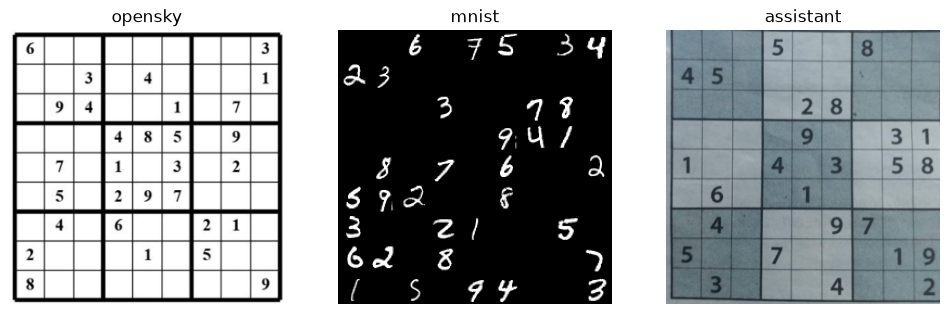

[[0 0 0 5 0 0 8 0 0]
 [4 5 0 0 0 0 0 0 0]
 [0 0 0 0 2 8 0 0 0]
 [0 0 0 0 9 0 0 3 1]
 [1 0 0 4 0 3 0 5 8]
 [0 6 0 0 1 0 0 0 0]
 [0 4 0 0 0 9 7 0 0]
 [5 0 0 7 0 0 0 1 9]
 [0 3 0 0 0 4 0 0 2]]


In [36]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4 * len(DATASETS), 4))
for ax, name in zip(np.atleast_1d(axes), DATASETS):
    img = DATA[name]["images"][0]
    ax.imshow(img.squeeze(), cmap="gray" if img.shape[-1] == 1 else None)
    ax.set_title(name)
    ax.axis("off")
plt.show()
print(DATA["assistant"]["labels"][0])

## 2. Preprocessing

1. **Segmentasi sel**: gambar dibagi menjadi 81 patch berukuran sama dengan sedikit overlap (`pad`) agar tahan terhadap rotasi kecil dan potongan yang tidak rapi.
2. **Penyesuaian ke backbone**: LeNet memakai 28×28 grayscale yang dibinerkan dengan *adaptive thresholding*, ResNet18 memakai 224×224 RGB dengan normalisasi ImageNet (128×128 kalau dijalankan tanpa GPU CUDA, agar muat di RAM laptop).
3. **Augmentasi**: rotasi, translasi, dan skala kecil secara acak saat training.
4. **Pembagian data**: train 60%, validation 20% (kalibrasi dan tuning α, γₑ), test 20%. Pembagian dilakukan per puzzle, bukan per sel.
5. **Penyeimbangan kelas**: sel blank sangat dominan, jadi kelas minoritas di-*upsample* dengan `WeightedRandomSampler`.

In [37]:
def split_cells(img, pad=0.0):
    # (H, W, C) uint8 -> (81, C, k+2o, k+2o) uint8, urut baris demi baris
    x = torch.from_numpy(img).permute(2, 0, 1).float()[None]
    k = x.shape[-1] // 9
    x = F.interpolate(x, size=(9 * k, 9 * k), mode="bilinear", align_corners=False)
    o = math.ceil(k * pad)
    x = F.pad(x, (o, o, o, o), mode="replicate")
    patches = x.unfold(2, k + 2 * o, k).unfold(3, k + 2 * o, k)[0]
    return patches.permute(1, 2, 0, 3, 4).reshape(81, x.shape[1], k + 2 * o, k + 2 * o).round().byte()


def adaptive_threshold(x, block=7, c=0.03):
    local_mean = F.avg_pool2d(x, block, stride=1, padding=block // 2, count_include_pad=False)
    return (x > local_mean + c).float()


IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def augment(x, degrees=5, translate=0.05, scale=0.05):
    # rotasi, translasi, dan skala acak per sampel dalam satu operasi batch
    n, dev = len(x), x.device
    ang = (torch.rand(n, device=dev) * 2 - 1) * math.radians(degrees)
    s = 1 + (torch.rand(n, device=dev) * 2 - 1) * scale
    shift = (torch.rand(n, 2, device=dev) * 2 - 1) * 2 * translate
    cos, sin = torch.cos(ang) / s, torch.sin(ang) / s
    theta = torch.stack([torch.stack([cos, -sin, shift[:, 0]], 1), torch.stack([sin, cos, shift[:, 1]], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode="border", align_corners=False)


def prepare_batch(patches, cfg, train=False):
    x = patches.to(DEVICE).float() / 255
    if train:
        x = augment(x)
    if cfg["arch"] == "lenet":
        x = x.mean(1, keepdim=True)
        # digit dibuat terang di atas latar gelap (seperti MNIST)
        border = torch.cat([x[..., 0, :], x[..., -1, :], x[..., :, 0], x[..., :, -1]], -1).mean(-1)
        x = torch.where(border.view(-1, 1, 1, 1) > 0.5, 1 - x, x)
        x = F.interpolate(x, size=(cfg["size"], cfg["size"]), mode="bilinear", align_corners=False)
        return adaptive_threshold(x)
    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    x = F.interpolate(x, size=(cfg["size"], cfg["size"]), mode="bilinear", align_corners=False)
    return (x - IMAGENET_MEAN.to(DEVICE)) / IMAGENET_STD.to(DEVICE)


for name, d in DATA.items():
    d["patches"] = torch.stack([split_cells(img, CFG[name]["pad"]) for img in d["images"]])
    print(f"{name:10s} patches={tuple(d['patches'].shape)}")

opensky    patches=(100, 81, 3, 41, 41)
mnist      patches=(1000, 81, 1, 28, 28)
assistant  patches=(103, 81, 3, 41, 41)


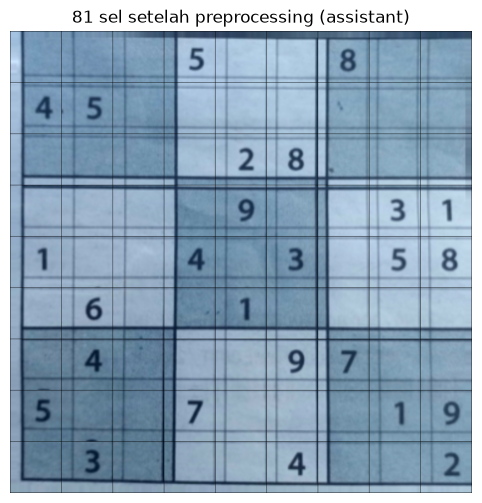

In [38]:
def split_indices(n, seed):
    perm = np.random.default_rng(seed).permutation(n)
    a, b = int(0.6 * n), int(0.8 * n)
    return {"train": perm[:a], "val": perm[a:b], "test": perm[b:]}


def cell_dataset(name, idx):
    d = DATA[name]
    x = d["patches"][idx].flatten(0, 1)
    y = torch.from_numpy(d["labels"][idx].reshape(-1)).long()
    return x, y


def balanced_sampler(y, n_classes):
    counts = torch.bincount(y, minlength=n_classes).float().clamp(min=1)
    weights = (1 / counts)[y]
    return torch.utils.data.WeightedRandomSampler(weights, num_samples=len(y), replacement=True)


name = "assistant" if "assistant" in DATA else DATASETS[0]
demo = prepare_batch(DATA[name]["patches"][0], CFG[name]).cpu()
grid = torchvision.utils.make_grid(demo, nrow=9, normalize=True, padding=1)
plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.title(f"81 sel setelah preprocessing ({name})")
plt.axis("off")
plt.show()

## 3. Training CNN (Persepsi)

Cell-CNN mengklasifikasi tiap sel secara independen dan mengeluarkan probabilitas:
- 10 kelas `{blank, 1, ..., 9}` untuk OpenSky dan MNIST
- 19 kelas `{blank, 1_printed, ..., 9_printed, 1_handwritten, ..., 9_handwritten}` untuk Sudoku Assistant

Backbone: LeNet untuk gambar sederhana dan ResNet18 *pretrained* ImageNet (di-*fine-tune*) untuk foto kamera HP. Model dengan akurasi sel validation terbaik disimpan ke `WEIGHTS_DIR`.

In [39]:
class LeNet(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build_model(cfg, pretrained=True):
    if cfg["arch"] == "lenet":
        return LeNet(cfg["classes"])
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, cfg["classes"])
    return model


@torch.no_grad()
def predict_logits(model, patches, cfg, bs=64):
    model.eval()
    out = [model(prepare_batch(patches[i:i + bs], cfg)).cpu() for i in range(0, len(patches), bs)]
    return torch.cat(out)


def train_cnn(name, seed):
    cfg = CFG[name]
    torch.manual_seed(seed)
    split = split_indices(len(DATA[name]["images"]), seed)
    x_tr, y_tr = cell_dataset(name, split["train"])
    x_va, y_va = cell_dataset(name, split["val"])
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(x_tr, y_tr), batch_size=cfg["bs"],
        sampler=balanced_sampler(y_tr, cfg["classes"]),
    )
    model = build_model(cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    best_acc, best_state, history = -1, None, []
    for epoch in range(cfg["epochs"]):
        model.train()
        total, n = 0.0, 0
        for xb, yb in loader:
            logits = model(prepare_batch(xb, cfg, train=True))
            loss = F.cross_entropy(logits, yb.to(DEVICE))
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(yb)
            n += len(yb)
        val_acc = (predict_logits(model, x_va, cfg).argmax(1) == y_va).float().mean().item()
        history.append(dict(epoch=epoch + 1, loss=total / n, val_acc=val_acc))
        print(f"  [{name} s{seed}] epoch {epoch + 1:2d}  loss {total / n:.4f}  val cell acc {val_acc:.4f}")
        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, split, history


def weight_path(name, seed):
    return WEIGHTS_DIR / f"{name}_s{seed}.pt"

In [40]:
MODELS, SPLITS, HISTORY = {}, {}, {}
for name in DATASETS:
    for seed in SEEDS:
        path = weight_path(name, seed)
        if TRAIN or not path.exists():
            t0 = time.time()
            model, split, history = train_cnn(name, seed)
            torch.save({"model": model.state_dict(), "split": split, "history": history, "cfg": CFG[name]}, path)
            print(f"{name} seed {seed}: selesai dalam {time.time() - t0:.0f} detik -> {path}")
        else:
            ckpt = torch.load(path, map_location="cpu", weights_only=False)
            CFG[name] = ckpt["cfg"]   # ukuran input harus sama dengan saat training
            model = build_model(ckpt["cfg"], pretrained=False)
            model.load_state_dict(ckpt["model"])
            split, history = ckpt["split"], ckpt["history"]
            print(f"{name} seed {seed}: bobot dimuat dari {path}")
        MODELS[name, seed] = model.to(DEVICE).eval()
        SPLITS[name, seed] = split
        HISTORY[name, seed] = history

opensky seed 0: bobot dimuat dari /Users/irham/Documents/ITS/File prodi Informatika/kka/program-csp/weights/opensky_s0.pt
mnist seed 0: bobot dimuat dari /Users/irham/Documents/ITS/File prodi Informatika/kka/program-csp/weights/mnist_s0.pt
assistant seed 0: bobot dimuat dari /Users/irham/Documents/ITS/File prodi Informatika/kka/program-csp/weights/assistant_s0.pt


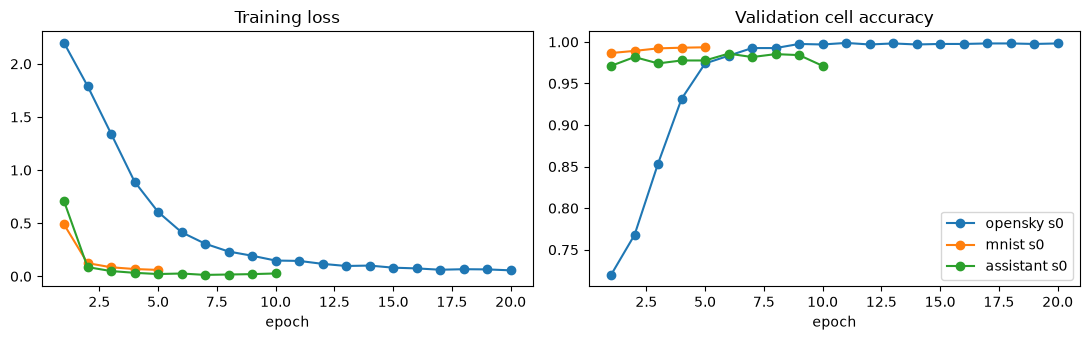

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for (name, seed), hist in HISTORY.items():
    h = pd.DataFrame(hist)
    axes[0].plot(h.epoch, h.loss, marker="o", label=f"{name} s{seed}")
    axes[1].plot(h.epoch, h.val_acc, marker="o", label=f"{name} s{seed}")
axes[0].set(title="Training loss", xlabel="epoch")
axes[1].set(title="Validation cell accuracy", xlabel="epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

## 4. Kalibrasi

Solver memakai −log P sebagai biaya, sehingga probabilitas CNN harus **terkalibrasi** (keyakinan 90% seharusnya benar sekitar 90% kasus). Tiga metode post-hoc dilatih di validation set dengan meminimalkan NLL:

| Metode | Parameter | Rumus |
|---|---|---|
| Temperature scaling | T (skalar) | softmax(z / T) |
| Vector scaling | w, b (vektor C) | softmax(w ⊙ z + b) |
| Matrix scaling | W (C×C), b | softmax(Wz + b) |

Kualitas kalibrasi diukur dengan **ECE** (Expected Calibration Error, 15 bin) dan **Brier score**.

In [42]:
class Calibrator(nn.Module):
    def __init__(self, kind, n_classes):
        super().__init__()
        self.kind = kind
        if kind == "temperature":
            self.log_t = nn.Parameter(torch.zeros(1))   # T = exp(log_t) selalu positif
        elif kind == "vector":
            self.w = nn.Parameter(torch.ones(n_classes))
            self.b = nn.Parameter(torch.zeros(n_classes))
        elif kind == "matrix":
            self.W = nn.Parameter(torch.eye(n_classes))
            self.b = nn.Parameter(torch.zeros(n_classes))

    def forward(self, z):
        if self.kind == "temperature":
            return z / self.log_t.exp()
        if self.kind == "vector":
            return z * self.w + self.b
        if self.kind == "matrix":
            return z @ self.W.T + self.b
        return z


def fit_calibrator(kind, logits, y, n_classes, l2=1e-3):
    cal = Calibrator(kind, n_classes)
    if kind == "none":
        return cal
    opt = torch.optim.LBFGS(cal.parameters(), lr=1, max_iter=200, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(cal(logits), y)
        if kind == "matrix":
            # regularisasi ke identitas, matrix scaling mudah overfit kalau data val sedikit
            loss = loss + l2 * ((cal.W - torch.eye(n_classes)) ** 2).sum()
        loss.backward()
        return loss

    opt.step(closure)
    return cal


def ece_score(probs, y, n_bins=15):
    conf, pred = probs.max(1)
    acc = (pred == y).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.float().mean() * (conf[mask].mean() - acc[mask].mean()).abs()
    return float(ece)


def brier_score(probs, y):
    return float(((probs - F.one_hot(y, probs.shape[1]).float()) ** 2).sum(1).mean())


CAL_KINDS = ["none", "temperature", "vector", "matrix"]

In [43]:
PROBS = {}   # PROBS[name, seed, kind, split] -> (n_puzzle, 9, 9, C)
cal_rows = []
for (name, seed), model in MODELS.items():
    cfg, split = CFG[name], SPLITS[name, seed]
    logits = {}
    for part in ["val", "test"]:
        x, y = cell_dataset(name, split[part])
        logits[part] = (predict_logits(model, x, cfg), y)
    for kind in CAL_KINDS:
        cal = fit_calibrator(kind, *logits["val"], cfg["classes"])
        with torch.no_grad():
            for part, (z, y) in logits.items():
                p = F.softmax(cal(z), 1)
                PROBS[name, seed, kind, part] = p.reshape(-1, 9, 9, cfg["classes"]).numpy().astype(np.float64)
                if part == "test":
                    cal_rows.append(dict(dataset=name, seed=seed, calibration=kind,
                                         cell_acc=float((p.argmax(1) == y).float().mean()),
                                         ECE=ece_score(p, y), Brier=brier_score(p, y)))

cal_df = pd.DataFrame(cal_rows)
cal_df.groupby(["dataset", "calibration"])[["cell_acc", "ECE", "Brier"]].mean().round(4)

cell_acc     ECE   Brier
dataset   calibration                          
assistant matrix         0.9877  0.0049  0.0191
          none           0.9888  0.0079  0.0206
          temperature    0.9888  0.0079  0.0208
          vector         0.9871  0.0081  0.0206
mnist     matrix         0.9956  0.0013  0.0075
          none           0.9938  0.0011  0.0097
          temperature    0.9938  0.0012  0.0097
          vector         0.9951  0.0010  0.0078
opensky   matrix         0.9981  0.0038  0.0033
          none           0.9975  0.0116  0.0052
          temperature    0.9975  0.0015  0.0041
          vector         0.9932  0.0068  0.0136

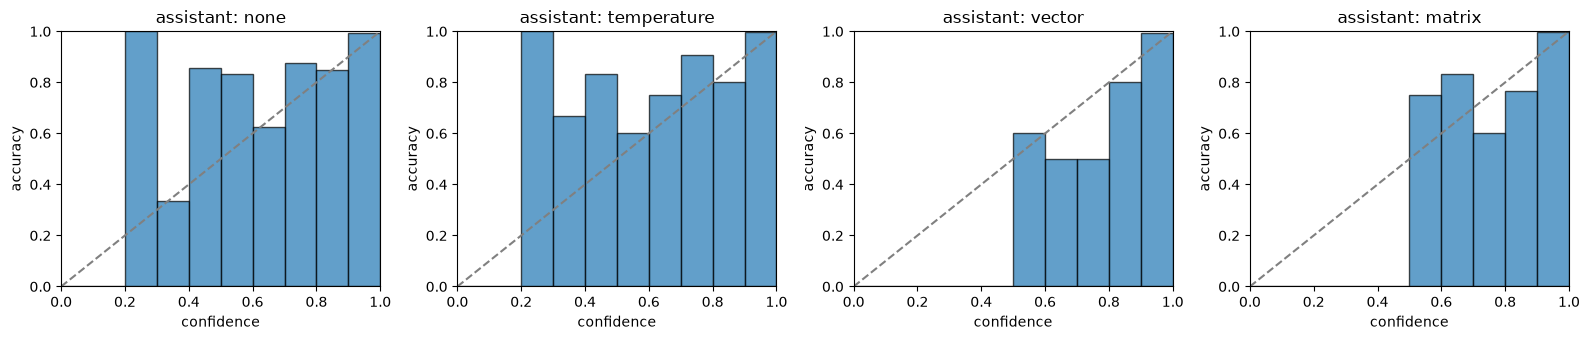

In [44]:
def reliability(ax, probs, y, title, n_bins=10):
    conf, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, n_bins + 1)
    accs = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        accs.append((pred[mask] == y[mask]).mean() if mask.any() else 0)
    ax.bar(edges[:-1], accs, width=1 / n_bins, align="edge", edgecolor="black", alpha=0.7)
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(title=title, xlabel="confidence", ylabel="accuracy", xlim=(0, 1), ylim=(0, 1))


name = "assistant" if "assistant" in DATASETS else DATASETS[0]
y_test = DATA[name]["labels"][SPLITS[name, SEEDS[0]]["test"]].reshape(-1)
fig, axes = plt.subplots(1, len(CAL_KINDS), figsize=(4 * len(CAL_KINDS), 3.5))
for ax, kind in zip(axes, CAL_KINDS):
    p = PROBS[name, SEEDS[0], kind, "test"].reshape(-1, CFG[name]["classes"])
    reliability(ax, p, y_test, f"{name}: {kind}")
plt.tight_layout()
plt.show()

## 5. Model CP & Solver

**Variabel**

| Variabel | Domain | Keterangan |
|---|---|---|
| `Y[r,c]` (perception) | {blank=0, 1, ..., 9} | bacaan CNN untuk sel (r,c) |
| `V[r,c]` (decision) | {1, ..., 9} | isian akhir solusi Sudoku |
| wildcard | `Y` diperluas menjadi {..., 10=wildcard} | bacaan sel diabaikan (khusus Sudoku Assistant) |

**Constraint**
- `C_rules`: AllDifferent pada tiap baris, kolom, dan blok 3×3 dari `V`
- Channelling: `Y[r,c] = k → V[r,c] = k` untuk k ∈ {1..9}
- `C_higher_order`: untuk satu bacaan `Y` tidak boleh ada dua solusi `V` berbeda. Kalau ada, bacaan `Y` itu dilarang (*nogood*) lalu solver mencari ulang.

**Fungsi objektif** (Pers. 16): minimalkan
$$L_\theta(X, Y) = -\sum_{r,c}\sum_{k \in D(Y_{rc})} [\![Y_{rc} = k]\!] \log P_\theta(Y_{rc} = k \mid X)$$

CP-SAT hanya menerima koefisien integer, jadi −log P dibagi `PRECISION` lalu dibulatkan. Bagian dalam sum dimodelkan sebagai *element constraint* `cost[r,c][Y[r,c]]`.

In [45]:
def to_cost(p):
    return np.round(-np.log(np.maximum(p, np.finfo(np.float32).eps)) / PRECISION).astype(int)


def reduce_to_ten(p):
    # 19 kelas -> 10 kelas: P(k) = P(k_printed) + P(k_handwritten)
    if p.shape[-1] == 10:
        return p
    return np.concatenate([p[..., :1], p[..., 1:10] + p[..., 10:19]], -1)


def status_name(solver):
    return solver.status().exitstatus.name.lower()


def is_unique(y, v):
    # apakah bacaan y hanya punya satu solusi (yaitu v)?
    W = cp.intvar(1, 9, shape=(9, 9), name="W")
    m = cp.Model(sudoku_rules(W))
    m += [W[i, j] == k for (i, j), k in np.ndenumerate(y) if 1 <= k <= 9]
    m += cp.any((W != v).flatten())
    return not m.solve("ortools", stop_after_first_solution=True)


def solve_joint(cost, forbid=None, higher_order=False, max_iter=100, time_limit=TIME_LIMIT):
    # cost: (9, 9, K) integer, K = 10 (blank, 1..9) atau 11 (+ wildcard)
    K = cost.shape[-1]
    V = cp.intvar(1, 9, shape=(9, 9), name="V")
    Y = cp.intvar(0, K - 1, shape=(9, 9), name="Y")
    m = cp.Model(sudoku_rules(V))
    m += [((Y[i, j] >= 1) & (Y[i, j] <= 9)).implies(V[i, j] == Y[i, j]) for i in range(9) for j in range(9)]
    if forbid is not None:
        m += [Y[i, j] != k for (i, j, k), f in np.ndenumerate(forbid) if f]
    m.minimize(cp.sum([cp.cpm_array(cost[i, j])[Y[i, j]] for i in range(9) for j in range(9)]))

    solver = cp.SolverLookup.get("ortools", m)
    t0 = time.time()
    found = solver.solve(time_limit=time_limit)
    nogoods = 0
    while found and higher_order and nogoods < max_iter:
        y, v = Y.value().copy(), V.value().copy()
        if is_unique(y, v):
            break
        solver += cp.any((Y != y).flatten())
        left = time_limit - (time.time() - t0)
        if left <= 0:
            found = False
            break
        found = solver.solve(time_limit=left)
        nogoods += 1
    return dict(
        found=bool(found), status=status_name(solver), runtime=time.time() - t0, nogoods=nogoods,
        Y=Y.value().copy() if found else None, V=V.value().copy() if found else None,
    )

### Metode inferensi

| Metode | Cara kerja |
|---|---|
| **Baseline** | argmax tiap sel, lalu angka hasil bacaan dijadikan *givens* untuk solver biasa. Satu salah baca bisa membuat puzzle tidak punya solusi. |
| **Hybrid** | *joint inference*: solver memilih bacaan `Y` paling mungkin yang memenuhi aturan (Pers. 16). Opsional `topk` untuk memangkas domain. |
| **Higher-order** | hybrid + pemeriksaan keunikan solusi dengan nogood (Pers. 17). |
| **Style-aware cost** | biaya tulisan tangan diberi bobot (1−α), cetak/blank diberi bobot α (Pers. 19). |
| **Style-aware prior + wildcard** | P(wildcard) = γₑ · P(handwritten); nilai dengan P < P(wildcard) dilarang (Pers. 20–22). |

In [46]:
def solve_baseline(p, time_limit=TIME_LIMIT):
    y = reduce_to_ten(p).argmax(-1)
    V = cp.intvar(1, 9, shape=(9, 9), name="V")
    m = cp.Model(sudoku_rules(V))
    m += [V[i, j] == k for (i, j), k in np.ndenumerate(y) if k > 0]
    t0 = time.time()
    found = m.solve("ortools", time_limit=time_limit)
    return dict(found=bool(found), status=m.status().exitstatus.name.lower(), runtime=time.time() - t0,
                nogoods=0, Y=y, V=V.value().copy() if found else None)


def topk_forbid(p10, k):
    if k is None:
        return None
    rank = np.argsort(np.argsort(-p10, -1), -1)
    return rank >= k


def solve_hybrid(p, topk=None, higher_order=False, time_limit=TIME_LIMIT):
    p10 = reduce_to_ten(p)
    return solve_joint(to_cost(p10), forbid=topk_forbid(p10, topk), higher_order=higher_order, time_limit=time_limit)


def solve_higher_order(p, topk=None, time_limit=TIME_LIMIT):
    return solve_hybrid(p, topk=topk, higher_order=True, time_limit=time_limit)


def style_cost(p19, alpha):
    # Pers. 19: alpha untuk blank/cetak, (1 - alpha) untuk tulisan tangan
    c = np.zeros((9, 9, 10))
    c[..., 0] = alpha * -np.log(np.maximum(p19[..., 0], 1e-7))
    c[..., 1:] = (alpha * -np.log(np.maximum(p19[..., 1:10], 1e-7))
                  + (1 - alpha) * -np.log(np.maximum(p19[..., 10:19], 1e-7)))
    return np.round(c / PRECISION).astype(int)


def solve_style_cost(p19, alpha=0.7, higher_order=False, time_limit=TIME_LIMIT):
    return solve_joint(style_cost(p19, alpha), higher_order=higher_order, time_limit=time_limit)


def solve_wildcard(p19, gamma=0.5, higher_order=False, time_limit=TIME_LIMIT):
    p10 = reduce_to_ten(p19)
    p_hw = p19[..., 10:19].sum(-1)
    p_wild = np.clip(gamma * p_hw, 1e-7, 1)                       # Pers. 21
    forbid = np.concatenate([p10 < p_wild[..., None], np.zeros((9, 9, 1), bool)], -1)  # Pers. 22a
    cost = to_cost(np.concatenate([p10, p_wild[..., None]], -1))  # domain Y + wildcard (Pers. 20)
    res = solve_joint(cost, forbid=forbid, higher_order=higher_order, time_limit=time_limit)
    res["wildcard"] = (res["Y"] == 10) if res["found"] else None
    return res

### Demo pada satu puzzle

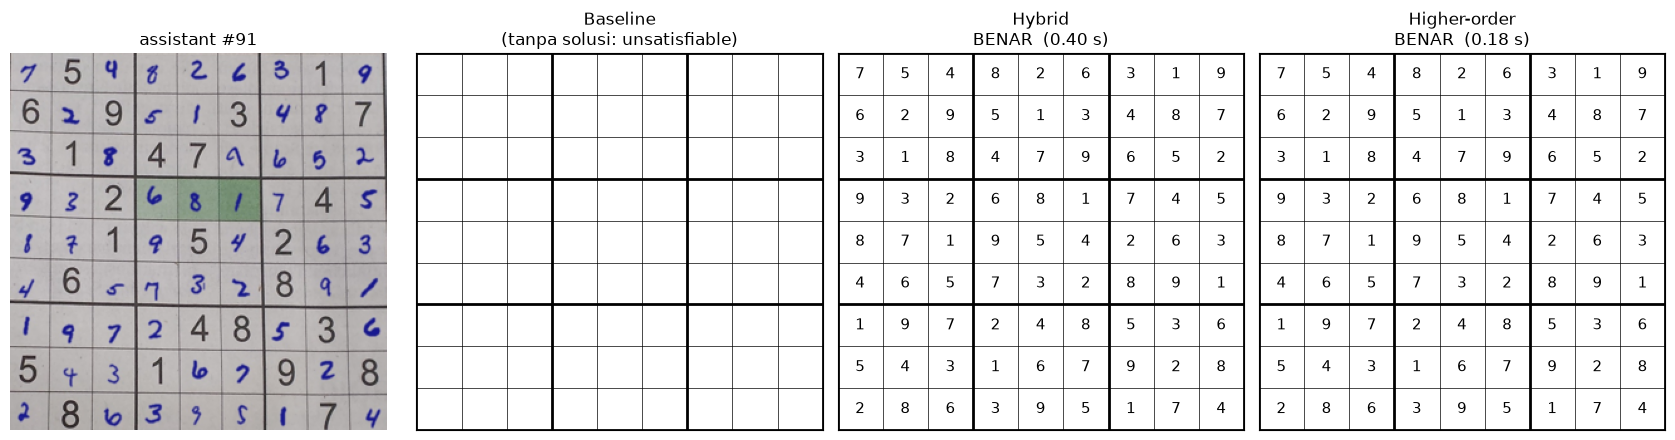

hitam: bacaan sesuai label, merah: bacaan dikoreksi solver, biru: diisi solver, oranye: wildcard, tebal: beda dengan solusi


In [47]:
def show_result(ax, digits_true, res, sol, title):
    ax.set_xlim(0, 9)
    ax.set_ylim(9, 0)
    for k in range(10):
        lw = 2 if k % 3 == 0 else 0.5
        ax.axhline(k, color="black", lw=lw)
        ax.axvline(k, color="black", lw=lw)
    ax.set_xticks([])
    ax.set_yticks([])
    if not res["found"]:
        ax.set_title(f"{title}\n(tanpa solusi: {res['status']})")
        return
    Y, V = res["Y"], res["V"]
    for (i, j), v in np.ndenumerate(V):
        if Y[i, j] == 10:
            color = "orange"      # wildcard
        elif 1 <= Y[i, j] <= 9:
            color = "black" if Y[i, j] == digits_true[i, j] else "red"   # bacaan solver beda dengan label
        else:
            color = "tab:blue"    # diisi solver
        weight = "bold" if v != sol[i, j] else "normal"
        ax.text(j + 0.5, i + 0.5, str(v), ha="center", va="center", color=color, fontsize=11, weight=weight)
    ok = np.array_equal(V, sol)
    ax.set_title(f"{title}\n{'BENAR' if ok else 'SALAH'}  ({res['runtime']:.2f} s)")


name = "assistant" if "assistant" in DATASETS else DATASETS[0]
seed = SEEDS[0]
probs = PROBS[name, seed, "temperature", "test"]
idx_test = SPLITS[name, seed]["test"]
# pilih puzzle yang baseline-nya gagal kalau ada, supaya terlihat efek joint inference
pick = next((n for n in range(len(probs)) if not np.array_equal(
    reduce_to_ten(probs[n]).argmax(-1), DATA[name]["digits"][idx_test[n]])), 0)
p, gid = probs[pick], idx_test[pick]

results = {
    "Baseline": solve_baseline(p),
    "Hybrid": solve_hybrid(p),
    "Higher-order": solve_higher_order(p),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
img = DATA[name]["images"][gid]
axes[0].imshow(img.squeeze(), cmap="gray" if img.shape[-1] == 1 else None)
axes[0].set_title(f"{name} #{gid}")
axes[0].axis("off")
for ax, (method, res) in zip(axes[1:], results.items()):
    show_result(ax, DATA[name]["digits"][gid], res, DATA[name]["solutions"][gid], method)
plt.tight_layout()
plt.show()
print("hitam: bacaan sesuai label, merah: bacaan dikoreksi solver, biru: diisi solver, oranye: wildcard, tebal: beda dengan solusi")

## 6. Evaluasi & Visualisasi

Metrik:
- **Cell accuracy** sebelum penalaran (argmax CNN) dan sesudah penalaran (bacaan `Y` hasil solver)
- **Grid accuracy**: persentase puzzle yang solusi `V`-nya sama persis dengan solusi sebenarnya
- **Tanpa solusi**: persentase puzzle yang tidak menemukan solusi dalam batas waktu
- **Waktu solver** rata-rata per puzzle

In [48]:
def evaluate(name, seed, probs, solve_fn, idx, digits=None, sols=None, **kw):
    digits = DATA[name]["digits"][idx] if digits is None else digits
    sols = DATA[name]["solutions"][idx] if sols is None else sols
    rows = []
    for p, dg, sol in zip(probs, digits, sols):
        res = solve_fn(p, **kw)
        before = reduce_to_ten(p).argmax(-1)
        after = np.where(res["Y"] == 10, -1, res["Y"]) if res["found"] else before
        rows.append(dict(
            cell_before=np.mean(before == dg), cell_after=np.mean(after == dg),
            grid=res["found"] and np.array_equal(res["V"], sol),
            no_solution=not res["found"], runtime=res["runtime"], nogoods=res["nogoods"],
        ))
    r = pd.DataFrame(rows)
    return dict(dataset=name, seed=seed, cell_before=r.cell_before.mean(), cell_after=r.cell_after.mean(),
                grid_acc=r.grid.mean(), no_solution=r.no_solution.mean(), runtime=r.runtime.mean(),
                nogoods=r.nogoods.mean())


def summarize(df, keys):
    cols = ["cell_before", "cell_after", "grid_acc", "no_solution", "runtime"]
    g = df.groupby(keys, sort=False)[cols]
    mean, std = g.mean(), g.std().fillna(0)
    out = mean.copy()
    for c in cols:
        fmt = "{:.3f}" if c == "runtime" else "{:.2%}"
        out[c] = [fmt.format(m) + (f" ± {fmt.format(s)}" if len(SEEDS) > 1 else "") for m, s in zip(mean[c], std[c])]
    return out

### Skenario 1: Perbandingan metode inferensi

Baseline vs Hybrid vs Higher-order pada ketiga dataset, memakai probabilitas yang sudah dikalibrasi dengan temperature scaling.

In [49]:
METHODS = {"Baseline": solve_baseline, "Hybrid": solve_hybrid, "Higher-order": solve_higher_order}
rows = []
for name in DATASETS:
    for seed in SEEDS:
        probs, idx = PROBS[name, seed, "temperature", "test"], SPLITS[name, seed]["test"]
        for method, fn in METHODS.items():
            rows.append(dict(method=method, **evaluate(name, seed, probs, fn, idx)))
            print(f"{name:10s} s{seed} {method:12s} grid acc {rows[-1]['grid_acc']:.2%}")
s1 = pd.DataFrame(rows)
summarize(s1, ["dataset", "method"])

opensky    s0 Baseline     grid acc 80.00%
opensky    s0 Hybrid       grid acc 95.00%
opensky    s0 Higher-order grid acc 100.00%
mnist      s0 Baseline     grid acc 58.50%
mnist      s0 Hybrid       grid acc 99.50%
mnist      s0 Higher-order grid acc 99.50%
assistant  s0 Baseline     grid acc 76.19%
assistant  s0 Hybrid       grid acc 95.24%
assistant  s0 Higher-order grid acc 100.00%


cell_before cell_after grid_acc no_solution runtime
dataset   method                                                          
opensky   Baseline          99.75%     99.75%   80.00%      20.00%   0.003
          Hybrid            99.75%     99.94%   95.00%       0.00%   0.145
          Higher-order      99.75%    100.00%  100.00%       0.00%   0.150
mnist     Baseline          99.38%     99.38%   58.50%      41.50%   0.002
          Hybrid            99.38%     99.99%   99.50%       0.00%   0.176
          Higher-order      99.38%     99.99%   99.50%       0.00%   0.167
assistant Baseline          99.29%     99.29%   76.19%      23.81%   0.003
          Hybrid            99.29%     99.94%   95.24%       0.00%   0.140
          Higher-order      99.29%    100.00%  100.00%       0.00%   0.158

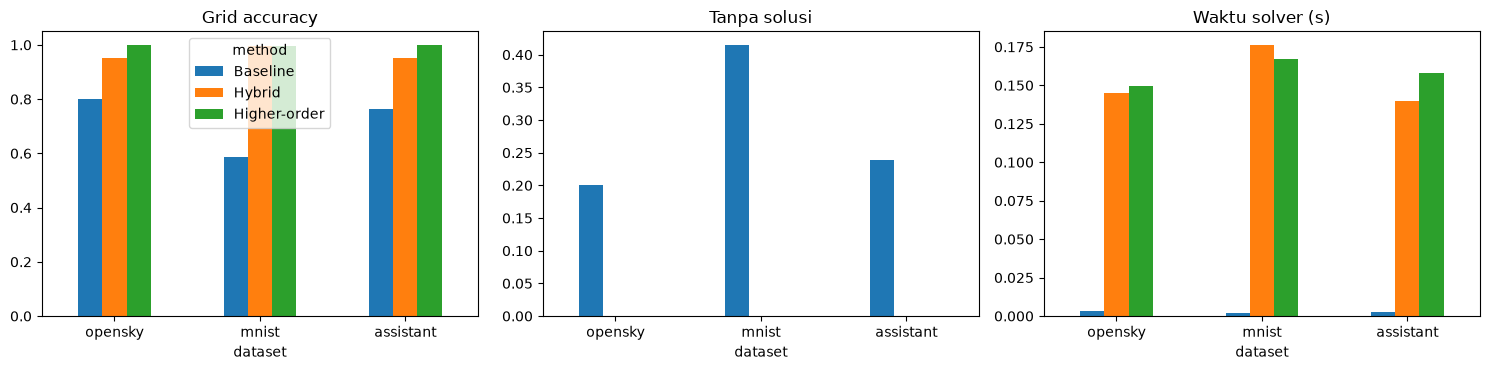

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, title) in zip(axes, [("grid_acc", "Grid accuracy"), ("no_solution", "Tanpa solusi"), ("runtime", "Waktu solver (s)")]):
    pivot = s1.groupby(["dataset", "method"], sort=False)[col].mean().unstack()[list(METHODS)]
    pivot.plot.bar(ax=ax, rot=0, legend=ax is axes[0])
    ax.set_title(title)
plt.tight_layout()
plt.show()

**Variasi top-k (Sudoku Assistant).** Domain `Y` dipangkas ke k kelas paling mungkin per sel. k kecil mempercepat solver, tetapi bisa membuang nilai yang benar sehingga puzzle tidak punya solusi.

In [51]:
if "assistant" in DATASETS:
    rows = []
    for seed in SEEDS:
        probs, idx = PROBS["assistant", seed, "temperature", "test"], SPLITS["assistant", seed]["test"]
        for k in [1, 2, 3, 5, None]:
            for method, fn in [("Hybrid", solve_hybrid), ("Higher-order", solve_higher_order)]:
                rows.append(dict(method=method, topk=str(k or "semua"), **evaluate("assistant", seed, probs, fn, idx, topk=k)))
    s1k = pd.DataFrame(rows)
    display(summarize(s1k, ["method", "topk"]))

,,cell_before,cell_after,grid_acc,no_solution,runtime
method,topk,,,,,
Hybrid,1,99.29%,99.29%,76.19%,23.81%,0.003
Higher-order,1,99.29%,99.29%,76.19%,23.81%,0.014
Hybrid,2,99.29%,99.59%,85.71%,9.52%,0.019
Higher-order,2,99.29%,99.53%,85.71%,9.52%,0.035
Hybrid,3,99.29%,99.65%,90.48%,4.76%,0.030
Higher-order,3,99.29%,99.71%,95.24%,4.76%,0.066
Hybrid,5,99.29%,99.94%,95.24%,0.00%,0.061
Higher-order,5,99.29%,100.00%,100.00%,0.00%,0.057
Hybrid,semua,99.29%,99.94%,95.24%,0.00%,0.150


### Skenario 2: Pengaruh kalibrasi

CNN tanpa kalibrasi dibandingkan dengan temperature, vector, dan matrix scaling. Dampaknya dilihat pada grid accuracy setelah penalaran dengan metode Hybrid.

In [52]:
rows = []
for name in DATASETS:
    for seed in SEEDS:
        idx = SPLITS[name, seed]["test"]
        for kind in CAL_KINDS:
            rows.append(dict(calibration=kind, **evaluate(name, seed, PROBS[name, seed, kind, "test"], solve_hybrid, idx)))
s2 = pd.DataFrame(rows).merge(cal_df, on=["dataset", "seed", "calibration"])
s2.groupby(["dataset", "calibration"], sort=False)[["ECE", "Brier", "cell_before", "grid_acc", "runtime"]].mean().round(4)

ECE   Brier  cell_before  grid_acc  runtime
dataset   calibration                                                
opensky   none         0.0116  0.0052       0.9975    0.9500   0.1723
          temperature  0.0015  0.0041       0.9975    0.9500   0.1429
          vector       0.0068  0.0136       0.9932    0.7000   0.1014
          matrix       0.0038  0.0033       0.9981    0.9500   0.1329
mnist     none         0.0011  0.0097       0.9938    0.9950   0.1731
          temperature  0.0012  0.0097       0.9938    0.9950   0.2021
          vector       0.0010  0.0078       0.9951    0.9900   0.2054
          matrix       0.0013  0.0075       0.9956    0.9950   0.1946
assistant none         0.0079  0.0206       0.9929    0.9524   0.1668
          temperature  0.0079  0.0208       0.9929    0.9524   0.1548
          vector       0.0081  0.0206       0.9906    0.9524   0.1461
          matrix       0.0049  0.0191       0.9906    0.9524   0.1667

### Skenario 3: Ketahanan terhadap kesalahan pengguna (Sudoku Assistant)

Mengikuti `CorruptSudoku` pada kode artikel: pada tiap puzzle uji dipilih sel kosong, lalu diisi angka tulisan tangan yang **salah** (bukan nilai solusi, dan tidak langsung bentrok dengan angka cetak di baris/kolom/blok yang sama). Gambar sel diganti dengan potongan angka tulisan tangan dari data train. Puzzle hasilnya menjadi tidak konsisten, dan sistem dinilai benar kalau tetap menemukan solusi asli.

Hyperparameter α (style-aware cost) dan γₑ (style-aware prior) dipilih di validation set yang diberi 2 kesalahan.

In [53]:
def hw_store(name, idx):
    # potongan sel tulisan tangan dari data train, dikelompokkan per angka
    d = DATA[name]
    store = {k: [] for k in range(1, 10)}
    for n in idx:
        for (i, j), k in np.ndenumerate(d["digits"][n]):
            if k > 0 and d["hw"][n, i, j]:
                store[k].append(d["patches"][n, i * 9 + j])
    return store


def corrupt(name, idx, n_err, store, seed):
    rng = np.random.default_rng(seed)
    d = DATA[name]
    patches = d["patches"][idx].clone()
    digits = d["digits"][idx].copy()
    for n in range(len(idx)):
        givens, sol = digits[n], d["solutions"][idx[n]]
        empties = [tuple(e) for e in np.argwhere(givens == 0)]
        rng.shuffle(empties)
        added = 0
        for i, j in empties:
            if added == n_err:
                break
            b_i, b_j = 3 * (i // 3), 3 * (j // 3)
            options = set(range(1, 10)) - {sol[i, j]} - set(givens[i]) - set(givens[:, j]) - set(givens[b_i:b_i + 3, b_j:b_j + 3].ravel())
            options = [k for k in options if store[k]]
            if not options:
                continue
            k = rng.choice(options)
            patches[n, i * 9 + j] = store[k][rng.integers(len(store[k]))]
            digits[n, i, j] = k
            added += 1
    return patches, digits


def corrupted_probs(name, seed, part, n_err, kind="temperature"):
    split, cfg = SPLITS[name, seed], CFG[name]
    idx = split[part]
    patches, digits = corrupt(name, idx, n_err, hw_store(name, split["train"]), seed=100 * seed + n_err)
    z = predict_logits(MODELS[name, seed], patches.flatten(0, 1), cfg)
    x_val, y_val = cell_dataset(name, split["val"])
    z_val = predict_logits(MODELS[name, seed], x_val, cfg)
    cal = fit_calibrator(kind, z_val, y_val, cfg["classes"])
    with torch.no_grad():
        p = F.softmax(cal(z), 1).reshape(-1, 9, 9, cfg["classes"]).numpy().astype(np.float64)
    return p, digits, idx

In [54]:
ALPHA, GAMMA = {}, {}
if "assistant" in DATASETS:
    for seed in SEEDS:
        p, digits, idx = corrupted_probs("assistant", seed, "val", n_err=2)
        sols = DATA["assistant"]["solutions"][idx]
        if TUNE:
            alpha_scores = {a: round(evaluate("assistant", seed, p, solve_style_cost, idx, digits, sols, alpha=a)["grid_acc"], 3)
                            for a in [0.5, 0.7, 0.9, 0.99]}
            gamma_scores = {g: round(evaluate("assistant", seed, p, solve_wildcard, idx, digits, sols, gamma=g)["grid_acc"], 3)
                            for g in [0.1, 0.3, 0.5, 0.9]}
            ALPHA[seed] = max(alpha_scores, key=alpha_scores.get)
            GAMMA[seed] = max(gamma_scores, key=gamma_scores.get)
            print(f"seed {seed}: grid acc per alpha {alpha_scores}, per gamma_e {gamma_scores}")
        else:
            ALPHA[seed], GAMMA[seed] = 0.9, 0.5
        print(f"seed {seed}: alpha = {ALPHA[seed]}, gamma_e = {GAMMA[seed]}")

seed 0: alpha = 0.9, gamma_e = 0.5


In [55]:
if "assistant" in DATASETS:
    rows = []
    for seed in SEEDS:
        a, g = ALPHA[seed], GAMMA[seed]
        methods = {
            "Hybrid": (solve_hybrid, {}),
            "Higher-order": (solve_higher_order, {}),
            f"Style-aware cost (α={a})": (solve_style_cost, dict(alpha=a)),
            f"Style-aware prior + wildcard (γ={g})": (solve_wildcard, dict(gamma=g)),
            "Style-aware prior + wildcard + higher-order": (solve_wildcard, dict(gamma=g, higher_order=True)),
        }
        for n_err in N_ERRORS:
            p, digits, idx = corrupted_probs("assistant", seed, "test", n_err)
            sols = DATA["assistant"]["solutions"][idx]
            for method, (fn, kw) in methods.items():
                method_key = method.split(" (")[0]
                rows.append(dict(method=method_key, n_errors=n_err,
                                 **evaluate("assistant", seed, p, fn, idx, digits, sols, **kw)))
            print(f"seed {seed}, {n_err} kesalahan selesai")
    s3 = pd.DataFrame(rows)
    display(s3.groupby(["method", "n_errors"], sort=False).grid_acc.mean().unstack().map("{:.2%}".format))

seed 0, 0 kesalahan selesai
seed 0, 1 kesalahan selesai
seed 0, 2 kesalahan selesai
seed 0, 5 kesalahan selesai


n_errors,0,1,2,5
method,,,,
Hybrid,95.24%,61.90%,28.57%,19.05%
Higher-order,100.00%,71.43%,38.10%,19.05%
Style-aware cost,95.24%,95.24%,95.24%,61.90%
Style-aware prior + wildcard,95.24%,95.24%,95.24%,95.24%
Style-aware prior + wildcard + higher-order,95.24%,95.24%,95.24%,95.24%


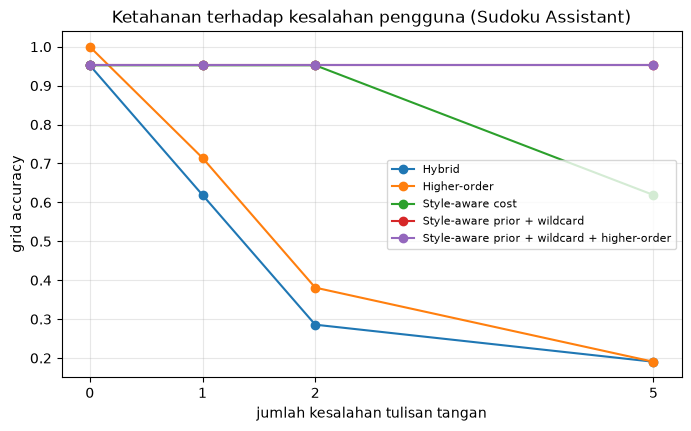

In [56]:
if "assistant" in DATASETS:
    plt.figure(figsize=(8, 4.5))
    for method, g in s3.groupby("method", sort=False):
        m = g.groupby("n_errors").grid_acc.mean()
        plt.plot(m.index, m.values, marker="o", label=method)
    plt.xticks(N_ERRORS)
    plt.xlabel("jumlah kesalahan tulisan tangan")
    plt.ylabel("grid accuracy")
    plt.title("Ketahanan terhadap kesalahan pengguna (Sudoku Assistant)")
    plt.legend(fontsize=8)
    plt.grid(alpha=0.3)
    plt.show()

### Visualisasi koreksi kesalahan pengguna

Satu puzzle uji dengan 2 angka tulisan tangan salah. Hybrid terpaksa mengubah sel lain atau gagal, sedangkan wildcard mengabaikan sel tulisan tangan yang berisiko (oranye) dan solver mengisi nilainya dari aturan Sudoku.

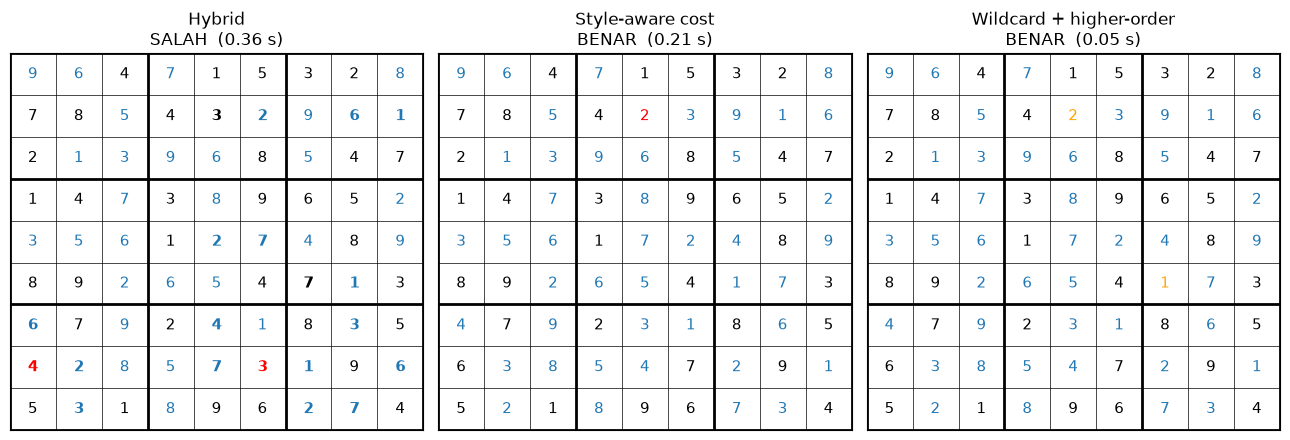

In [57]:
if "assistant" in DATASETS:
    seed = SEEDS[0]
    p, digits, idx = corrupted_probs("assistant", seed, "test", n_err=2)
    n = 0
    sol = DATA["assistant"]["solutions"][idx[n]]
    res = {
        "Hybrid": solve_hybrid(p[n]),
        "Style-aware cost": solve_style_cost(p[n], alpha=ALPHA[seed]),
        "Wildcard + higher-order": solve_wildcard(p[n], gamma=GAMMA[seed], higher_order=True),
    }
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
    for ax, (method, r) in zip(axes, res.items()):
        show_result(ax, digits[n], r, sol, method)
    plt.tight_layout()
    plt.show()

### Ringkasan

Tabel gabungan seluruh skenario. Hasil yang diharapkan sesuai artikel:
1. Joint inference (Hybrid/Higher-order) memperbaiki kesalahan baca CNN sehingga grid accuracy lebih tinggi dan persentase tanpa solusi turun dibanding Baseline.
2. Kalibrasi menurunkan ECE dan membantu kualitas solusi.
3. Membedakan tulisan tangan dan angka cetak (style-aware prior + wildcard) membuat sistem tetap bisa menemukan solusi asli walaupun pengguna menulis angka yang salah.

In [58]:
print("Skenario 1")
display(summarize(s1, ["dataset", "method"]))
print("Skenario 2")
display(summarize(s2, ["dataset", "calibration"]))
if "assistant" in DATASETS:
    print("Skenario 3")
    display(summarize(s3, ["method", "n_errors"]))

Skenario 1


cell_before cell_after grid_acc no_solution runtime
dataset   method                                                          
opensky   Baseline          99.75%     99.75%   80.00%      20.00%   0.003
          Hybrid            99.75%     99.94%   95.00%       0.00%   0.145
          Higher-order      99.75%    100.00%  100.00%       0.00%   0.150
mnist     Baseline          99.38%     99.38%   58.50%      41.50%   0.002
          Hybrid            99.38%     99.99%   99.50%       0.00%   0.176
          Higher-order      99.38%     99.99%   99.50%       0.00%   0.167
assistant Baseline          99.29%     99.29%   76.19%      23.81%   0.003
          Hybrid            99.29%     99.94%   95.24%       0.00%   0.140
          Higher-order      99.29%    100.00%  100.00%       0.00%   0.158

Skenario 2


cell_before cell_after grid_acc no_solution runtime
dataset   calibration                                                    
opensky   none             99.75%     99.94%   95.00%       0.00%   0.172
          temperature      99.75%     99.94%   95.00%       0.00%   0.143
          vector           99.32%     99.44%   70.00%       0.00%   0.101
          matrix           99.81%     99.94%   95.00%       0.00%   0.133
mnist     none             99.38%     99.99%   99.50%       0.00%   0.173
          temperature      99.38%     99.99%   99.50%       0.00%   0.202
          vector           99.51%     99.99%   99.00%       0.00%   0.205
          matrix           99.56%     99.99%   99.50%       0.00%   0.195
assistant none             99.29%     99.94%   95.24%       0.00%   0.167
          temperature      99.29%     99.94%   95.24%       0.00%   0.155
          vector           99.06%     99.76%   95.24%       0.00%   0.146
          matrix           99.06%     99.88%   95.24%       0.00%   0.167

Skenario 3


,,cell_before,cell_after,grid_acc,no_solution,runtime
method,n_errors,,,,,
Hybrid,0,99.29%,99.94%,95.24%,0.00%,0.197
Higher-order,0,99.29%,100.00%,100.00%,0.00%,0.192
Style-aware cost,0,99.29%,99.00%,95.24%,0.00%,0.201
Style-aware prior + wildcard,0,99.29%,99.18%,95.24%,0.00%,0.038
Style-aware prior + wildcard + higher-order,0,99.29%,99.18%,95.24%,0.00%,0.357
Hybrid,1,99.29%,99.00%,61.90%,0.00%,0.281
Higher-order,1,99.29%,99.00%,71.43%,0.00%,0.600
Style-aware cost,1,99.29%,98.00%,95.24%,0.00%,0.219
Style-aware prior + wildcard,1,99.29%,98.18%,95.24%,0.00%,0.039


## 7. Demo Web (Gradio)

Antarmuka web untuk mendemokan pipeline CNN + CP pada satu puzzle:

- **Tab "Upload foto"**: unggah foto Sudoku sendiri (file, kamera, atau clipboard). Kotak 9×9 dideteksi otomatis dengan OpenCV (kontur segi empat terbesar yang punya pola garis grid), lalu diluruskan dengan *perspective warp* ke 300×300 seperti data Sudoku Assistant. Kalau deteksi meleset, matikan "Deteksi kotak otomatis" dan pakai alat crop di editor foto.
- **Tab "Puzzle dari dataset"**: pilih dataset dan nomor puzzle dari test set. Untuk Sudoku Assistant, bisa disisipkan kesalahan tulisan tangan seperti Skenario 3.

Hasil yang ditampilkan:
- **Foto yang dibaca**: foto setelah dipotong, dengan garis bantu 9×9 untuk mengecek apakah sel sudah pas.
- **Solusi**: hitam = bacaan dipakai, biru = diisi solver, merah = bacaan CNN dikoreksi solver, oranye = isian tulisan tangan yang salah (wildcard). Angka kecil dicoret adalah angka yang terbaca di foto.
- **Laporan**: daftar sel bermasalah lengkap dengan baris, kolom, angka tertulis, dan angka seharusnya, ditambah konflik aturan (angka kembar di baris, kolom, atau blok) pada bacaan CNN.
- **Detail bacaan CNN**: argmax tiap sel (ungu = keyakinan < 90%, miring = tulisan tangan) dan 81 potongan sel.

Isian salah hanya bisa ditunjuk dengan model **assistant** dan metode **Wildcard + higher-order**, karena hanya model itu yang membedakan angka cetak dan tulisan tangan. Metode lain tetap menampilkan sel yang diubah solver.

Di laptop, web terbuka di `http://127.0.0.1:7860`. Di Colab, Gradio memberi link publik `*.gradio.live`.

In [59]:
if IN_COLAB:
    !pip -q install gradio

In [ ]:
import html

import cv2
import gradio as gr

DEMO_SEED = SEEDS[0]
_CAL_CACHE = {}


def demo_calibrator(name):
    # temperature scaling, dilatih ulang sekali di validation set lalu disimpan
    if name not in _CAL_CACHE:
        x_val, y_val = cell_dataset(name, SPLITS[name, DEMO_SEED]["val"])
        z_val = predict_logits(MODELS[name, DEMO_SEED], x_val, CFG[name])
        _CAL_CACHE[name] = fit_calibrator("temperature", z_val, y_val, CFG[name]["classes"])
    return _CAL_CACHE[name]


def demo_probs(name, patches):
    z = predict_logits(MODELS[name, DEMO_SEED], patches, CFG[name])
    with torch.no_grad():
        p = F.softmax(demo_calibrator(name)(z), 1)
    return p.reshape(9, 9, -1).numpy().astype(np.float64)


def run_method(method, p):
    if method == "Baseline":
        return solve_baseline(p)
    if method == "Hybrid":
        return solve_hybrid(p)
    if method == "Higher-order":
        return solve_higher_order(p)
    gamma = globals().get("GAMMA", {}).get(DEMO_SEED, 0.5)
    return solve_wildcard(p, gamma=gamma, higher_order=True)


# ---------- deteksi kotak Sudoku di foto ----------

def order_corners(pts):
    # urutan: kiri atas, kanan atas, kanan bawah, kiri bawah
    s, d = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[s.argmin()], pts[d.argmin()], pts[s.argmax()], pts[d.argmax()]])


def warp_grid(img, corners, size=300):
    dst = np.float32([[0, 0], [size, 0], [size, size], [0, size]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(corners, dst), (size, size), flags=cv2.INTER_AREA)


def grid_score(th, corners, size=270):
    # seberapa banyak piksel garis di posisi garis grid 9x9 setelah diluruskan
    w = warp_grid(th, corners, size) > 0
    pos = [round(k * size / 9) for k in range(1, 9)]
    lines = [w[max(c - 2, 0):c + 3].any(0).mean() for c in pos] + [w[:, max(c - 2, 0):c + 3].any(1).mean() for c in pos]
    return float(np.mean(lines))


def hull_quad(c):
    # sederhanakan convex hull kontur menjadi 4 titik sudut
    hull = cv2.convexHull(c)
    peri = cv2.arcLength(hull, True)
    for eps in (0.02, 0.04, 0.06, 0.08):
        approx = cv2.approxPolyDP(hull, eps * peri, True)
        if len(approx) == 4:
            return order_corners(approx.reshape(4, 2).astype(np.float32))
    return None


def find_grid(img, min_area=0.1, min_score=0.5):
    # kandidat kotak: kontur besar dan jaringan garis grid (tetap terdeteksi walau tepi luar terpotong),
    # ditambah seluruh foto (kalau sudah dicrop). Dipilih yang garis 9x9-nya paling cocok,
    # jadi kertas atau bingkai foto yang juga segi empat tidak terpilih.
    # Hasil None berarti foto dipakai apa adanya.
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    f = min(1.0, 1000 / max(gray.shape))
    gray = cv2.resize(gray, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    h, w = gray.shape
    th = cv2.adaptiveThreshold(cv2.GaussianBlur(gray, (5, 5), 0), 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 15, 4)
    th = cv2.dilate(th, np.ones((3, 3), np.uint8))
    n = max(h, w) // 25
    lines = cv2.morphologyEx(th, cv2.MORPH_OPEN, np.ones((1, n), np.uint8)) | cv2.morphologyEx(th, cv2.MORPH_OPEN, np.ones((n, 1), np.uint8))
    lines = cv2.dilate(lines, np.ones((5, 5), np.uint8))

    full = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
    best, best_score = full, grid_score(th, full)
    for mask, mode in ((th, cv2.RETR_LIST), (lines, cv2.RETR_EXTERNAL)):
        contours, _ = cv2.findContours(mask, mode, cv2.CHAIN_APPROX_SIMPLE)
        for c in sorted(contours, key=cv2.contourArea, reverse=True)[:15]:
            if cv2.contourArea(cv2.convexHull(c)) < min_area * gray.size:
                break
            corners = hull_quad(c)
            if corners is None:
                continue
            score = grid_score(th, corners)
            if score > best_score:
                best, best_score = corners, score
    if best_score < min_score or best is full:
        return None
    return best / f


def grid_overlay(img):
    # garis bantu 9x9 untuk mengecek apakah sel sudah pas
    out = img.copy()
    n = out.shape[0]
    for k in range(1, 9):
        c = round(k * n / 9)
        cv2.line(out, (c, 0), (c, n), (220, 38, 38), 1, cv2.LINE_AA)
        cv2.line(out, (0, c), (n, c), (220, 38, 38), 1, cv2.LINE_AA)
    return out


def patches_to_image(patches, pad):
    # kebalikan split_cells: buang overlap tiap patch lalu susun lagi jadi satu papan
    s = patches.shape[-1]
    k = next(k for k in range(s, 0, -1) if k + 2 * math.ceil(k * pad) == s)
    o = (s - k) // 2
    x = patches[:, :, o:o + k, o:o + k].reshape(9, 9, -1, k, k).permute(0, 3, 1, 4, 2).reshape(9 * k, 9 * k, -1)
    x = x.numpy()
    return np.repeat(x, 3, -1) if x.shape[-1] == 1 else x


def patches_image(patches):
    x = patches.float() / 255
    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    grid = torchvision.utils.make_grid(x, nrow=9, padding=2, pad_value=1.0)
    return (grid.permute(1, 2, 0).numpy() * 255).astype(np.uint8)


# ---------- analisis hasil: posisi kesalahan dan konflik aturan ----------

def read_cells(p):
    p10 = reduce_to_ten(p)
    read, conf = p10.argmax(-1), p10.max(-1)
    if p.shape[-1] == 19:
        hw = (read > 0) & (p[..., 10:19].sum(-1) > p[..., 1:10].sum(-1))
    else:
        hw = np.zeros((9, 9), bool)
    return read, conf, hw


def find_issues(read, hw, res):
    # (baris, kolom, terbaca, seharusnya, keterangan), baris dan kolom mulai dari 1
    if not res["found"]:
        return []
    Y, V = res["Y"], res["V"]
    rows = []
    for (i, j), y in np.ndenumerate(Y):
        r = read[i, j]
        if y == 10:
            note = "Isian tulisan tangan salah, diabaikan solver"
        elif r > 0 and y == 0:
            note = "Solver menganggap sel ini kosong"
        elif r > 0 and y != r:
            note = "Isian tulisan tangan diganti solver" if hw[i, j] else "Salah baca CNN, dikoreksi solver"
        else:
            continue
        rows.append((i + 1, j + 1, int(r), int(V[i, j]), note, y == 10))
    return rows


def rule_conflicts(read):
    # angka kembar pada bacaan CNN di baris, kolom, atau blok 3x3
    units = [(f"Baris {i + 1}", [(i, j) for j in range(9)]) for i in range(9)]
    units += [(f"Kolom {j + 1}", [(i, j) for i in range(9)]) for j in range(9)]
    units += [(f"Blok baris {bi + 1}-{bi + 3}, kolom {bj + 1}-{bj + 3}",
               [(bi + i, bj + j) for i in range(3) for j in range(3)])
              for bi in range(0, 9, 3) for bj in range(0, 9, 3)]
    out = []
    for name, cells in units:
        for v in range(1, 10):
            pos = [c for c in cells if read[c] == v]
            if len(pos) > 1:
                where = ", ".join(f"({i + 1},{j + 1})" for i, j in pos)
                out.append(f"{name}: angka {v} muncul {len(pos)} kali di {where}")
    return out


# ---------- tampilan HTML ----------

def grid_html(values, cls, old=None, title="", legend=()):
    head = "<tr><th></th>" + "".join(f"<th>{j + 1}</th>" for j in range(9)) + "</tr>"
    body = []
    for i in range(9):
        tds = []
        for j in range(9):
            v = values[i, j]
            mark = f'<s class="old">{old[i][j]}</s>' if old is not None and old[i][j] else ""
            tds.append(f'<td class="{cls[i][j]}">{mark}{v if v > 0 else ""}</td>')
        body.append(f"<tr><th>{i + 1}</th>{''.join(tds)}</tr>")
    keys = "".join(f'<span><i class="sw {c}"></i>{t}</span>' for c, t in legend)
    return (f'<div class="board"><h3>{title}</h3><table class="sgrid">{head}{"".join(body)}</table>'
            f'<div class="legend">{keys}</div></div>')


def read_grid_html(read, conf, hw):
    cls = [[("hw" if hw[i, j] else "pr") + (" low" if conf[i, j] < 0.9 else "") for j in range(9)] for i in range(9)]
    return grid_html(read, cls, title="Bacaan CNN",
                     legend=[("pr", "Angka cetak"), ("hw", "Tulisan tangan"), ("low", "Yakin < 90%")])


def solution_html(read, hw, res):
    if not res["found"]:
        return ('<div class="board"><h3>Solusi</h3><p class="empty">Solver tidak menemukan solusi '
                f'({html.escape(res["status"])}).</p></div>')
    Y, V = res["Y"], res["V"]
    cls = [[""] * 9 for _ in range(9)]
    old = [[""] * 9 for _ in range(9)]
    for (i, j), y in np.ndenumerate(Y):
        r = read[i, j]
        if y == 10:
            cls[i][j], old[i][j] = "wild", r
        elif r > 0 and y != r:
            cls[i][j], old[i][j] = "fix", r
        elif r > 0:
            cls[i][j] = "hw" if hw[i, j] else "pr"
        else:
            cls[i][j] = "fill"
    legend = [("pr", "Dari foto"), ("fill", "Diisi solver"), ("fix", "Dikoreksi solver"), ("wild", "Isian salah")]
    return grid_html(V, cls, old, "Solusi", legend)


def report_html(read, hw, res, method, model_name, sol=None, digits=None, notes=()):
    issues = find_issues(read, hw, res)
    conflicts = rule_conflicts(read)
    n_wrong = sum(w for *_, w in issues)
    if not res["found"]:
        verdict, tone = "Solver tidak menemukan solusi. Periksa konflik aturan di bawah atau coba metode lain.", "bad"
    elif n_wrong:
        verdict, tone = f"Ada {n_wrong} isian yang salah. Posisinya ada di tabel di bawah.", "warn"
    elif issues:
        verdict, tone = f"Solusi ditemukan setelah {len(issues)} bacaan dikoreksi solver.", "warn"
    else:
        verdict, tone = "Semua isian sesuai aturan Sudoku. Solusi lengkap ditampilkan.", "ok"
    parts = [f'<div class="verdict {tone}">{verdict}</div>']
    if sol is not None:
        ok = res["found"] and np.array_equal(res["V"], sol)
        parts.append(f'<div class="verdict {"ok" if ok else "bad"}">Dibanding solusi sebenarnya: '
                     f'{"BENAR" if ok else "SALAH"}</div>')

    if issues:
        rows = "".join(f'<tr class="{"wrong" if w else ""}"><td>{r}</td><td>{c}</td><td>{t or "kosong"}</td>'
                       f"<td>{v}</td><td>{note}</td></tr>" for r, c, t, v, note, w in issues)
        parts.append(f'<h4>Sel bermasalah ({len(issues)})</h4><div class="scroll"><table class="tbl"><tr><th>Baris</th><th>Kolom</th>'
                     f"<th>Terbaca</th><th>Seharusnya</th><th>Keterangan</th></tr>{rows}</table></div>")
    elif res["found"]:
        parts.append("<h4>Sel bermasalah</h4><p>Tidak ada.</p>")
    if conflicts:
        items = "".join(f"<li>{c}</li>" for c in conflicts)
        parts.append(f"<h4>Konflik aturan pada bacaan CNN ({len(conflicts)})</h4><ul>{items}</ul>")
    if not n_wrong and method != "Wildcard + higher-order":
        parts.append('<p class="hint">Untuk menunjuk isian tulisan tangan yang salah, pakai model assistant '
                     "dengan metode Wildcard + higher-order.</p>")

    stats = [("Model CNN", model_name), ("Metode", method), ("Status solver", res["status"]),
             ("Waktu solver", f"{res['runtime']:.3f} detik")]
    if res.get("nogoods"):
        stats.append(("Nogood (higher-order)", res["nogoods"]))
    if digits is not None:
        stats.append(("Akurasi sel CNN", f"{np.mean(read == digits):.2%}"))
    rows = "".join(f"<tr><th>{k}</th><td>{v}</td></tr>" for k, v in stats)
    parts.append(f'<h4>Ringkasan</h4><table class="tbl kv">{rows}</table>')
    parts += [f'<p class="hint">{html.escape(n)}</p>' for n in notes if n]
    return '<div class="report">' + "".join(parts) + "</div>"


def solve_and_render(p, method, model_name, sol=None, digits=None, notes=()):
    notes = list(notes)
    if method.startswith("Wildcard") and p.shape[-1] == 10:
        notes.append("Wildcard butuh model 19 kelas (assistant), dipakai Higher-order.")
        method = "Higher-order"
    res = run_method(method, p)
    read, conf, hw = read_cells(p)
    return (solution_html(read, hw, res), report_html(read, hw, res, method, model_name, sol, digits, notes),
            read_grid_html(read, conf, hw))

In [ ]:
def solve_from_dataset(name, n, method, n_err):
    idx = SPLITS[name, DEMO_SEED]["test"]
    n = int(min(max(n, 0), len(idx) - 1))
    gid = idx[n]
    notes = [f"Puzzle {name} #{gid} (test ke-{n})."]
    if n_err > 0 and name == "assistant":
        split = SPLITS[name, DEMO_SEED]
        patches, digits = corrupt(name, np.array([gid]), int(n_err), hw_store(name, split["train"]), seed=n)
        patches, digits = patches[0], digits[0]
        added = int(np.sum(digits != DATA[name]["digits"][gid]))
        if added < n_err:
            notes.append(f"Hanya {added} kesalahan yang bisa disisipkan karena sel kosong di puzzle ini terbatas.")
    else:
        if n_err > 0:
            notes.append("Kesalahan tulisan tangan hanya tersedia untuk dataset Sudoku Assistant.")
        patches, digits = DATA[name]["patches"][gid], DATA[name]["digits"][gid]
    p = demo_probs(name, patches)
    sol_html, report, read_html = solve_and_render(p, method, name, DATA[name]["solutions"][gid], digits, notes)
    return patches_to_image(patches, CFG[name]["pad"]), sol_html, report, read_html, patches_image(patches)


def solve_from_upload(editor, auto_crop, model_name, method):
    img = editor.get("composite") if isinstance(editor, dict) else editor
    if img is None:
        return None, EMPTY_SOL, '<div class="report"><div class="verdict bad">Unggah foto Sudoku terlebih dahulu.</div></div>', EMPTY_READ, None
    if img.ndim == 2:
        img = np.stack([img] * 3, -1)
    img = np.ascontiguousarray(img[..., :3]).astype(np.uint8)
    notes = []
    corners = find_grid(img) if auto_crop else None
    if corners is not None:
        img = warp_grid(img, corners)
    else:
        if auto_crop:
            notes.append("Kotak Sudoku tidak terdeteksi, foto dipakai apa adanya. Matikan deteksi otomatis "
                         "lalu crop manual di editor supaya pas di garis tepi kotak.")
        img = np.asarray(T.functional.resize(T.functional.to_pil_image(img), [300, 300]))
    # data training berupa angka gelap di latar terang, jadi foto diubah ke abu-abu
    # dan warnanya dibalik kalau latarnya gelap (median < 128)
    gray = img.mean(-1).astype(np.uint8)
    if np.median(gray) < 128:
        gray = 255 - gray
        notes.append("Latar foto gelap, warna foto dibalik sebelum dibaca CNN.")
    img = np.stack([gray] * 3, -1)
    shown = grid_overlay(img)
    if model_name == "mnist":
        img = gray[..., None]
    patches = split_cells(img, CFG[model_name]["pad"])
    p = demo_probs(model_name, patches)
    sol_html, report, read_html = solve_and_render(p, method, model_name, notes=notes)
    return shown, sol_html, report, read_html, patches_image(patches)


METHOD_CHOICES = ["Baseline", "Hybrid", "Higher-order", "Wildcard + higher-order"]
DEFAULT_MODEL = "assistant" if "assistant" in DATASETS else DATASETS[0]

THEME = gr.themes.Base(
    primary_hue=gr.themes.colors.blue,
    neutral_hue=gr.themes.colors.slate,
    radius_size=gr.themes.sizes.radius_sm,
    text_size=gr.themes.sizes.text_md,
    font=[gr.themes.GoogleFont("Poppins"), "ui-sans-serif", "system-ui", "sans-serif"],
).set(
    body_background_fill="#f5f6f8",
    body_text_color="#1f2937",
    block_background_fill="#ffffff",
    block_border_color="#e2e5ea",
    block_shadow="none",
    block_label_text_weight="600",
    button_primary_background_fill="#1d4ed8",
    button_primary_background_fill_hover="#1e40af",
    button_primary_text_color="#ffffff",
)

CSS = """
.gradio-container { max-width: 1280px !important; margin: 0 auto !important; }
.head-block .html-container { padding: 0 !important; }
/* kanvas kosong editor foto disembunyikan sampai ada foto */
#photo-editor .image-container:has(> .empty) .pixi-target,
#photo-editor .image-container:has(> .empty) .pixi-target-crop { visibility: hidden; }
.app-head { display: flex; justify-content: space-between; align-items: flex-end; gap: 16px;
            border-bottom: 1px solid #e2e5ea; padding: 4px 0 14px; }
.app-head h1 { font-size: 26px; font-weight: 600; margin: 0 0 4px; color: #111827; }
.app-head p { margin: 0; color: #4b5563; font-size: 14px; }
.app-head .meta { text-align: right; color: #4b5563; font-size: 13px; line-height: 1.5; }
.board h3, .report h4 { font-size: 15px; font-weight: 600; color: #111827; margin: 0 0 10px; }
.report h4 { margin-top: 18px; }
.report h4:first-child { margin-top: 0; }
.sgrid { border-collapse: collapse; margin: 0 auto; font-variant-numeric: tabular-nums; }
.sgrid th { font-size: 11px; font-weight: 500; color: #9ca3af; width: 18px; padding: 0 4px !important;
            border: none !important; background: none !important; text-align: center; }
.sgrid td { width: 38px; height: 38px; text-align: center; vertical-align: middle; position: relative;
            border: 1px solid #d1d5db; font-size: 20px; font-weight: 500; color: #111827; background: #fff; padding: 0; }
.sgrid tr:nth-child(2) td { border-top: 2px solid #111827; }
.sgrid tr:nth-child(4) td, .sgrid tr:nth-child(7) td { border-bottom: 2px solid #111827; }
.sgrid tr:last-child td { border-bottom: 2px solid #111827; }
.sgrid td:nth-child(2) { border-left: 2px solid #111827; }
.sgrid td:nth-child(4), .sgrid td:nth-child(7), .sgrid td:last-child { border-right: 2px solid #111827; }
.sgrid td.hw { font-style: italic; color: #374151; }
.sgrid td.low { color: #7e22ce; background: #f5edfc; }
.sgrid td.fill { color: #1d4ed8; font-weight: 400; }
.sgrid td.fix { color: #b91c1c; background: #fdeaea; }
.sgrid td.wild { color: #b45309; background: #fdf0dc; }
.sgrid s.old { position: absolute; top: 1px; left: 3px; font-size: 11px; font-style: normal; color: #6b7280; }
.legend { display: flex; flex-wrap: wrap; justify-content: center; gap: 6px 14px; margin-top: 10px;
          font-size: 12px; color: #4b5563; }
.legend span { display: inline-flex; align-items: center; gap: 6px; }
.legend .sw { display: inline-block; width: 12px; height: 12px; border: 1px solid #9ca3af; }
.sw.pr { background: #111827; } .sw.hw { background: #6b7280; } .sw.low { background: #c084fc; }
.sw.fill { background: #1d4ed8; } .sw.fix { background: #dc2626; } .sw.wild { background: #f59e0b; }
.board .empty { color: #b91c1c; padding: 40px 0; text-align: center; }
.verdict { border-left: 4px solid; padding: 10px 14px; margin-bottom: 8px; font-weight: 500; font-size: 15px; }
.verdict.ok { border-color: #15803d; background: #eaf6ee; color: #14532d; }
.verdict.warn { border-color: #d97706; background: #fdf3e3; color: #78350f; }
.verdict.bad { border-color: #dc2626; background: #fdeaea; color: #7f1d1d; }
.tbl { border-collapse: collapse; width: 100%; font-size: 14px; border: none !important; }
.tbl th, .tbl td { border: none !important; border-bottom: 1px solid #e5e7eb !important; padding: 7px 10px !important; text-align: left; }
.tbl th { color: #4b5563; font-weight: 600; background: #f9fafb; }
.tbl tr.wrong td { background: #fdf0dc; }
.tbl.kv th { width: 40%; background: none; font-weight: 500; }
.report ul { margin: 0; padding-left: 20px; font-size: 14px; }
.report .hint { color: #6b7280; font-size: 13px; margin: 10px 0 0; }
.report .scroll { overflow-x: auto; }
.report table, .report tbody, .report tr { border: none !important; }
.report .scroll .tbl { min-width: 560px; }
.report .scroll .tbl td, .report .scroll .tbl th { white-space: nowrap; }
@media (max-width: 720px) {
  .res-row { flex-direction: column !important; }
  .sgrid td { width: 32px; height: 32px; font-size: 17px; }
  .app-head { flex-direction: column; align-items: flex-start; }
  .app-head .meta { text-align: left; }
}
"""

# paksa mode terang walaupun sistem memakai dark mode
FORCE_LIGHT = """
() => {
    const url = new URL(window.location);
    if (url.searchParams.get("__theme") !== "light") {
        url.searchParams.set("__theme", "light");
        window.location.replace(url.href);
    }
}
"""

# isi awal panel hasil sebelum tombol Solve ditekan
_BLANK = np.zeros((9, 9), int)
EMPTY_SOL = grid_html(_BLANK, [[""] * 9] * 9, title="Solusi",
                      legend=[("pr", "Dari foto"), ("fill", "Diisi solver"), ("fix", "Dikoreksi solver"), ("wild", "Isian salah")])
EMPTY_READ = grid_html(_BLANK, [[""] * 9] * 9, title="Bacaan CNN",
                       legend=[("pr", "Angka cetak"), ("hw", "Tulisan tangan"), ("low", "Yakin < 90%")])
EMPTY_REPORT = ('<div class="report"><h4>Laporan</h4><p class="hint">Unggah foto Sudoku atau pilih puzzle dari dataset, '
                "lalu tekan Solve. Sel yang salah akan ditampilkan lengkap dengan baris dan kolomnya.</p></div>")

with gr.Blocks(title="Visual Sudoku Solver") as demo:
    gr.HTML(
        '<div class="app-head"><div><h1>Visual Sudoku Solver</h1>'
        "<p>CNN membaca foto Sudoku, lalu Constraint Programming (CP-SAT) mencari solusi yang memenuhi aturan.</p></div>"
        '<div class="meta">Kelompok 5 KKA<br>Implementasi Mulamba dkk. (2024)</div></div>',
        elem_classes="head-block",
    )
    with gr.Row():
        with gr.Column(scale=4, min_width=320):
            with gr.Tab("Upload foto"):
                up = gr.ImageEditor(
                    label="Foto Sudoku", type="numpy", image_mode="RGB", height=380,
                    sources=("upload", "webcam", "clipboard"), transforms=("crop",),
                    brush=False, eraser=False, layers=False,
                    placeholder="Seret foto ke sini, ambil dari kamera, atau tempel dari clipboard",
                    elem_id="photo-editor",
                )
                auto_up = gr.Checkbox(value=True, label="Deteksi kotak otomatis",
                                      info="Matikan kalau hasil deteksi meleset, lalu crop manual di editor.")
                model_up = gr.Dropdown(DATASETS, value=DEFAULT_MODEL, label="Model CNN")
                method_up = gr.Radio(METHOD_CHOICES, value="Wildcard + higher-order", label="Metode",
                                     info="Wildcard + higher-order bisa menunjuk isian tulisan tangan yang salah.")
                btn_up = gr.Button("Solve", variant="primary")
            with gr.Tab("Puzzle dari dataset"):
                ds = gr.Dropdown(DATASETS, value=DEFAULT_MODEL, label="Dataset")
                num = gr.Slider(0, len(SPLITS[DEFAULT_MODEL, DEMO_SEED]["test"]) - 1, value=0, step=1, label="Nomor puzzle (test set)")
                err = gr.Slider(0, 5, value=0, step=1, label="Sisipkan kesalahan tulisan tangan",
                                info="Khusus dataset assistant, seperti Skenario 3.")
                method_ds = gr.Radio(METHOD_CHOICES, value="Wildcard + higher-order", label="Metode")
                btn_ds = gr.Button("Solve", variant="primary")
        with gr.Column(scale=7):
            with gr.Row(equal_height=True, elem_classes="res-row"):
                out_photo = gr.Image(label="Foto yang dibaca", interactive=False, height=480, scale=1)
                out_sol = gr.HTML(EMPTY_SOL, container=True, padding=True, scale=1, min_width=440)
            out_report = gr.HTML(EMPTY_REPORT, container=True, padding=True)
            with gr.Accordion("Detail bacaan CNN", open=False):
                with gr.Row(equal_height=True, elem_classes="res-row"):
                    out_read = gr.HTML(EMPTY_READ, container=True, padding=True, scale=1, min_width=440)
                    out_cells = gr.Image(label="81 sel yang masuk ke CNN", interactive=False, height=480, scale=1)

    outputs = [out_photo, out_sol, out_report, out_read, out_cells]
    ds.change(lambda name: gr.update(maximum=len(SPLITS[name, DEMO_SEED]["test"]) - 1, value=0), ds, num)
    btn_ds.click(solve_from_dataset, [ds, num, method_ds, err], outputs)
    btn_up.click(solve_from_upload, [up, auto_up, model_up, method_up], outputs)

demo.launch(share=IN_COLAB, inbrowser=not IN_COLAB, theme=THEME, css=CSS, js=FORCE_LIGHT)